# Visions

A complete RNN model showcasing the power of recursively calculating the value of a sentence. This allows the model to understand the order of words
and how that effects the context and overall sentence.

### Part 1: Preprocessing - Robert

Here we preprocess out data by creating a vocabulary dictionary and sorting it, as well as tokenizing all of the sentences in the data.

In [2]:
with open("data/qa1_train.txt") as f:
    lines = f.readlines()[:1010] # open file and read first 1010 lines


tokens = []

for line in lines:
    words = line.lower().strip().split(' ') # lowercase, strip trailing newlines, and split on whitespace
    words = words[1:] # remove line number
    tokens.append(words)




# same setup as week 11
vocab = set()

for sent in tokens:
    for word in sent:
        vocab.add(word)

vocab = sorted(vocab)




# same as week 11
word2index = {word: i for i, word in enumerate(vocab)}


# The following function takes the sentences from the data folder and turns each word into their respective indice from the set above.
def words2indices(sentence):
    return [word2index[word] for word in sentence]



if __name__ == "__main__":
    print(len(lines))

    # test. If this works, we should see line 1 of qa1_train.text written out in lower case
    print(tokens[0])

    # test. Should get 82 and the full list. *** Note made after tests, read the comments at the BOTTOM of the file
    print("Vocabulary Size:", len(vocab))
    print(sorted(vocab))

    # test. Should output the number corresponding to where mary is in the set
    print(word2index["mary"])

    # test. Should turn line 1 in the data folder to its respective indices
    print(words2indices(tokens[0]))

1010
['mary', 'moved', 'to', 'the', 'bathroom.']
Vocabulary Size: 82
['\tbathroom\t1', '\tbathroom\t10', '\tbathroom\t11', '\tbathroom\t13', '\tbathroom\t14', '\tbathroom\t2', '\tbathroom\t4', '\tbathroom\t5', '\tbathroom\t7', '\tbathroom\t8', '\tbedroom\t1', '\tbedroom\t10', '\tbedroom\t11', '\tbedroom\t13', '\tbedroom\t14', '\tbedroom\t2', '\tbedroom\t4', '\tbedroom\t5', '\tbedroom\t7', '\tbedroom\t8', '\tgarden\t1', '\tgarden\t10', '\tgarden\t11', '\tgarden\t13', '\tgarden\t14', '\tgarden\t2', '\tgarden\t4', '\tgarden\t5', '\tgarden\t7', '\tgarden\t8', '\thallway\t1', '\thallway\t10', '\thallway\t11', '\thallway\t13', '\thallway\t14', '\thallway\t2', '\thallway\t4', '\thallway\t5', '\thallway\t7', '\thallway\t8', '\tkitchen\t1', '\tkitchen\t10', '\tkitchen\t11', '\tkitchen\t13', '\tkitchen\t14', '\tkitchen\t2', '\tkitchen\t4', '\tkitchen\t5', '\tkitchen\t7', '\tkitchen\t8', '\toffice\t1', '\toffice\t10', '\toffice\t11', '\toffice\t13', '\toffice\t14', '\toffice\t2', '\toffice\t4', '

### Part 2: RNN Forward Pass - Kevin

Here we implement an RNN forward pass. The recursive nature of predicting in an RNN is the key here.

In [3]:
import numpy as np

#Initialize the four weight tensors and one-hot matrix using seed 1.
def init_weights(vocab_size, embed_size=10):
    np.random.seed(1)
    
    embed = (np.random.rand(vocab_size, embed_size) - 0.5) * 0.1
    recurrent = np.eye(embed_size)
    start = np.zeros(embed_size)
    decoder = (np.random.rand(embed_size, vocab_size) - 0.5) * 0.1
    one_hot = np.eye(vocab_size)
    
    return embed, recurrent, start, decoder, one_hot

#Compute numerically stable softmax by subtracting the maximum value.
def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / np.sum(e_x)

def predict(sent, embed, recurrent, start, decoder):
    # Layer 0 holds the initial start state; it has no 'pred' of its own
    layers = [{'hidden': start}]
    total_loss = 0.0
    
    for layer_idx, target_word_idx in enumerate(sent):
        # Predict the next word distribution using the hidden state from the previous layer
        prev_hidden = layers[layer_idx]['hidden']
        pred = softmax(prev_hidden.dot(decoder))
        
        # Accumulate cross-entropy loss for the target word
        loss = -np.log(pred[target_word_idx])
        total_loss += loss
        
        # Compute the new hidden state by combining recurrence and word embedding
        next_hidden = prev_hidden.dot(recurrent) + embed[target_word_idx]
        
        # Append layer dictionary containing hidden state and prediction distribution
        layers.append({
            'hidden': next_hidden,
            'pred': pred
        })
        
    return layers, total_loss

#Compute per-step perplexity: exp(total_loss / len(sent)).
def compute_perplexity(total_loss, sent_len):
    division = total_loss / sent_len
    return np.exp(division)

### Part 3: RNN Backprop Through Time - Brady

Here we is the backpropagation through time which is the heart of the model's training by combining 2 separate deltas during backprop, one for the prediction of a word at that point through the decoder, and the effect of that layers value on future predictions.

In [11]:
import numpy as np
from rnn_forward import predict, compute_perplexity

def backward_pass(sent, layers, decoder, recurrent, one_hot):
    # Walk backward through the layers
    for layer_idx in reversed(range(1, len(layers))):
        target = sent[layer_idx - 1]
        layer = layers[layer_idx]
        layer['output_delta'] = layer['pred'] - one_hot[target]
        
        new_hidden_delta = layer['output_delta'].dot(decoder.T)
        
        if layer_idx == len(layers) - 1:
            layer['hidden_delta'] = new_hidden_delta
        else:
            layer['hidden_delta'] = (
                new_hidden_delta
                + layers[layer_idx + 1]['hidden_delta'].dot(recurrent.T)
            )
            
    # calculate the hidden delta for the starting layer
    layers[0]['hidden_delta'] = (
        layers[1]['hidden_delta'].dot(recurrent.T)
    )
    return layers

def train_step(sent, embed, recurrent, start, decoder, one_hot, alpha):
    # This will run the forward pass
    layers, total_loss = predict(
        sent, embed, recurrent, start, decoder
    )

    # Run the backward pass to calculate deltas
    layers = backward_pass(sent, layers, decoder, recurrent, one_hot)

    # calculate the learning rate
    step_size = alpha / len(sent)
    
    # update the starting hidden state
    start -= layers[1]['hidden_delta'] * step_size
    
    for layer_idx, layer in enumerate(layers[1:]):
        decoder -= np.outer(
            layers[layer_idx]['hidden'],
            layer['output_delta']
        ) * step_size
        
        if layer_idx + 2 < len(layers):
            # get the hidden gradient for the word
            grad_h = layers[layer_idx + 2]['hidden_delta']
            # update the word embedding weights
            embed[sent[layer_idx]] -= grad_h * step_size
            # update the recurrent weights
            recurrent -= np.outer(
                layers[layer_idx]['hidden'],
                grad_h
            ) * step_size
            
    perplexity = compute_perplexity(total_loss, len(sent))
    return perplexity

### Part 4 - Elijah

This is the actual full training loop for the model on the data which also produces a log of the perplexities over time and the final trained weights.
It implements the previously created functions for the full loop.

In [ ]:
import numpy as np
from rnn_forward import compute_perplexity, init_weights
from rnn_bptt import train_step

TRAIN_N = 1000

alpha = .001
iterations = 30000

def train(alpha, iters, TRAIN_N):
    #initialize the weights
    embed, recurrent, start, decoder, one_hot = init_weights(vocab_size=len(word2index))

    perplexity_log = []
    
    # Main loop
    for it in range(iters):
        # Get the current sentence. it % train_n will cycle through the first TRAIN_N lines
        #  however many times it/TRAIN_N is
        sent = words2indices(tokens[it % TRAIN_N][1:])

        # train the model this step and get perplexity
        perplexity = train_step(sent, embed, recurrent, start, decoder, one_hot, alpha)

        # every 1000 iters, add the current iteration and perplexity to a log of the training
        if (it+1) % 1000 == 0:
            perplexity_log.append((it+1, perplexity))
            print((it+1, perplexity))

    # save the log of the perplexities
    np.savetxt('perplexity_log.csv', perplexity_log, delimiter=',')

    np.savez(
        "trained_weights.npz",
        embed=embed,
        recurrent=recurrent,
        start=start,
        decoder=decoder
    )

if __name__ == "__main__":
    train(alpha, iterations, TRAIN_N)

(1000, np.float64(81.74202246471971))
(2000, np.float64(81.56981632336928))
(3000, np.float64(81.29380551020232))
(4000, np.float64(80.81785963368341))
(5000, np.float64(79.95994897989425))
(6000, np.float64(78.34677936029622))
(7000, np.float64(75.12701017100169))
(8000, np.float64(68.02261771017713))
(9000, np.float64(50.31848194091786))
(10000, np.float64(32.43306029110547))
(11000, np.float64(25.134903546461178))
(12000, np.float64(19.745575438349807))
(13000, np.float64(15.596594358573546))
(14000, np.float64(12.409495894016077))
(15000, np.float64(9.836484869184813))
(16000, np.float64(7.988284044572278))
(17000, np.float64(6.806696442205551))
(18000, np.float64(6.039820223909579))
(19000, np.float64(5.5026282017541535))
(20000, np.float64(5.1005197921767405))
(21000, np.float64(4.781544014654082))
(22000, np.float64(4.51682893601824))
(23000, np.float64(4.292145866317458))
(24000, np.float64(4.100641058284432))
(25000, np.float64(3.937836972919754))
(26000, np.float64(3.79982139

#### Perplexity Log Plot

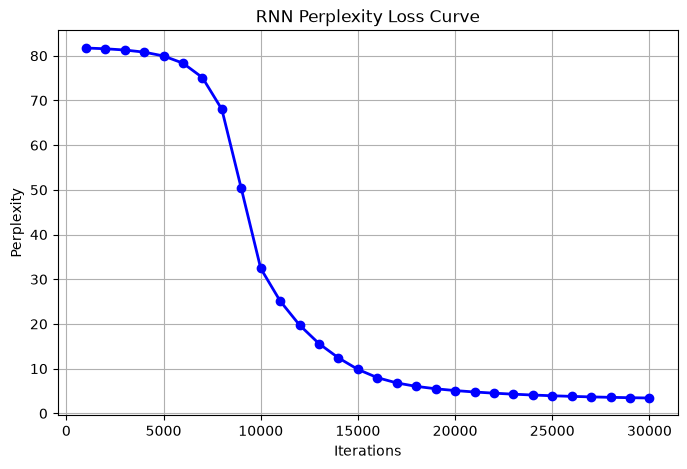

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Load saved perplexity data
log_data = np.loadtxt('perplexity_log.csv', delimiter=',')

iterations = log_data[:, 0]
perplexities = log_data[:, 1]

# Display inline plot
plt.figure(figsize=(8, 5))
plt.plot(iterations, perplexities, color='blue', marker='o', linewidth=2)
plt.title('RNN Perplexity Loss Curve')
plt.xlabel('Iterations')
plt.ylabel('Perplexity')
plt.grid(True)
plt.show()

### Part 5 - Colson

This shows a comparison between the model actually predicting the next words on some test sentences and reality. It showcases the power of our model and its shortcomings.

In [15]:
import numpy as np


from rnn_forward import predict


weights = np.load("trained_weights.npz")

embed = weights["embed"]
recurrent = weights["recurrent"]
start = weights["start"]
decoder = weights["decoder"]

# select three statements
test_indices = [1004, 1005, 1006]

for i in test_indices:
    sentence = tokens[i][1:]
    sent = words2indices(sentence)

    print(f"Sentence {i}: {sentence}")
    # run the sentence through the trained RNN
    layers, loss = predict(sent, embed, recurrent, start, decoder)

    
    print(f"{'Context':<25} {'Actual':<15} {'Predicted':<15}")
    print("-" * 55)

    for layer_idx in range(2, len(layers)):
        prediction = layers[layer_idx]["pred"]
        # get the word with the highest predicted probability
        predicted_idx = np.argmax(prediction)
        predicted_word = vocab[predicted_idx]

        # get words already seen and the actual next word
        context = " ".join(sentence[:layer_idx - 1])
        actual_word = sentence[layer_idx - 1]

        print(f"{context:<25} {actual_word:<15} {predicted_word:<15}")


Sentence 1004: ['is', 'sandra?', '\thallway\t14']
Context                   Actual          Predicted      
-------------------------------------------------------
is                        sandra?         to             
is sandra?                	hallway	14     the            
Sentence 1005: ['journeyed', 'to', 'the', 'bedroom.']
Context                   Actual          Predicted      
-------------------------------------------------------
journeyed                 to              to             
journeyed to              the             the            
journeyed to the          bedroom.        bedroom.       
Sentence 1006: ['moved', 'to', 'the', 'office.']
Context                   Actual          Predicted      
-------------------------------------------------------
moved                     to              to             
moved to                  the             the            
moved to the              office.         bedroom.       


### Part 6: Unit Tests - Kevin

Tests to prove that our functions work.

In [17]:
import numpy as np
from rnn_forward import init_weights, softmax, predict, compute_perplexity
from rnn_bptt import train_step, backward_pass

def test_preprocessing():
    """
    Test 1: Preprocessing test.
    Verifies that vocabulary size is 82 and word2index round-trips hand-picked words.
    """
    # Verify vocabulary size
    assert len(vocab) == 82, f"Expected vocabulary size 82, got {len(vocab)}"
    
    # Test round-trip mapping for hand-picked words
    test_words = ['mary', 'bathroom.', 'went', 'hallway.']
    for word in test_words:
        assert word in word2index, f"Word '{word}' missing from word2index"
        idx = word2index[word]
        assert vocab[idx] == word, f"Round-trip failed for word '{word}'"
        
    print('PASS: test_preprocessing')

def test_softmax():
    """
    Test 2: Softmax stability and normalization test.
    Verifies output sums to 1.0 (within 1e-9) and uniform distribution for zero vector.
    """
    # Check sum to 1.0 for arbitrary input
    vec = np.array([1.5, -2.3, 10.0, 0.4])
    probs = softmax(vec)
    assert abs(np.sum(probs) - 1.0) < 1e-9, f"Softmax sum is {np.sum(probs)}, expected 1.0"
    
    # Check uniform distribution for zero vector
    zero_vec = np.zeros(5)
    uniform_probs = softmax(zero_vec)
    expected_prob = 1.0 / 5.0
    assert np.allclose(uniform_probs, expected_prob), 'Softmax on zero vector is not uniform'
    
    print('PASS: test_softmax')

def test_forward_shape():
    """
    Test 3: Forward pass output shape and untrained perplexity test.
    Verifies predict returns len(sent) + 1 layers and perplexity in [80, 84].
    """
    embed, recurrent, start, decoder, _ = init_weights(len(vocab))
    sent = words2indices(tokens[0][1:])
    
    layers, total_loss = predict(sent, embed, recurrent, start, decoder)
    
    # Verify layer count
    assert len(layers) == len(sent) + 1, f"Expected {len(sent) + 1} layers, got {len(layers)}"
    
    # Verify untrained perplexity range [80, 84]
    perplexity = compute_perplexity(total_loss, len(sent))
    assert 80.0 <= perplexity <= 84.0, f"Perplexity {perplexity:.2f} outside [80, 84]"
    
    print('PASS: test_forward_shape')

def test_training_decreases_loss():
    """
    Test 4: Fixed sentence training convergence test.
    Verifies that running 100 training steps on a single fixed sentence reduces perplexity.
    """
    embed, recurrent, start, decoder, one_hot = init_weights(len(vocab))
    sent = words2indices(tokens[0][1:])
    
    # Initial loss/perplexity
    _, initial_loss = predict(sent, embed, recurrent, start, decoder)
    initial_perp = compute_perplexity(initial_loss, len(sent))
    
    # Run 100 training steps on the same fixed sentence
    alpha = 0.01
    for _ in range(100):
        train_step(sent, embed, recurrent, start, decoder, one_hot, alpha=alpha)
        
    _, final_loss = predict(sent, embed, recurrent, start, decoder)
    final_perp = compute_perplexity(final_loss, len(sent))
    
    assert final_perp < initial_perp, f"Training failed to reduce perplexity: initial {initial_perp:.2f}, final {final_perp:.2f}"
    
    print('PASS: test_training_decreases_loss')

def test_hidden_delta_sum():
    """
    Test 5: BPTT hidden delta sum test.
    Verifies that for sentence length >= 3, intermediate hidden delta includes the 
    second component pulled through recurrent.T rather than output_delta alone.
    """
    embed, recurrent, start, decoder, one_hot = init_weights(len(vocab))
    sent = words2indices(tokens[0][1:])  # Sentence length >= 3
    
    # Perform forward pass
    layers, _ = predict(sent, embed, recurrent, start, decoder)
    
    # Perform backward pass to compute deltas without updating weights
    layers = backward_pass(sent, layers, decoder, recurrent, one_hot)
    
    # Direct component calculation for comparison
    target_idx = sent[0]
    out_delta = layers[1]['pred'].copy()
    out_delta[target_idx] -= 1.0
    direct_component = out_delta.dot(decoder.T)
    
    actual_hidden_delta = layers[1]['hidden_delta']
    
    # Verify hidden delta includes the recurrent backpropagation piece
    assert not np.allclose(actual_hidden_delta, direct_component), \
        'Hidden delta only contains output delta component; missing recurrent backpropagation piece!'
        
    print('PASS: test_hidden_delta_sum')

def main():
    # Run all test suites and output PASS/FAIL status.
    tests = [
        test_preprocessing,
        test_softmax,
        test_forward_shape,
        test_training_decreases_loss,
        test_hidden_delta_sum
    ]
    
    passed = 0
    failed = 0
    
    print('Running Visions Test Suite')
    for test_fn in tests:
        try:
            test_fn()
            passed += 1
        except Exception as e:
            print(f"FAIL: {test_fn.__name__} - {e}")
            failed += 1
            
    print(f"\nSummary: {passed} passed, {failed} failed.")

main()

Running Visions Test Suite
PASS: test_preprocessing
PASS: test_softmax
PASS: test_forward_shape
PASS: test_training_decreases_loss
PASS: test_hidden_delta_sum

Summary: 5 passed, 0 failed.


### Part 7 - Elijah

An explanation of the Holocron's warning for this week and what it means for the model to learn structure vs understanding.

## Holocron -- Reading

*HOLOCRON NOTE — from the holocron of Vael Korrith — intact
“The first sign is the smallest. The student begins to finish the sentence before the
master has spoken it, and pride replaces listening. They will tell you they have under-
stood the technique so well it has become them. Be afraid in that hour. The technique
has not become them. They have become it.”*

##### Response

The model correctly predicted all of sentence 1005 starting with the first word as context. This correctness is NOT generalization of our model. This model only works on sentences that have similar structures and vocabularies as those it was trained on, and even then, it will never be able to predict with high accuracies words that could be interchangeably placed in a sentence while keeping structure like as shown in the prediciton for sentence 1004. The model doesn't predict "kitchen" because it holds the exact same effect on the sentence as "bedroom." And a sentence it had never seen before would completely stump the model because it will not have any data on the words or sentence structure; it would just spit out garbage. The warning from the holocron explains this well. The model will confidently predict something that it simply cannot know without knowing a greater context to the sentence. As an engineer, to learn to trust the speech of this model, you should run a test that sees if the model is adding information into sentences that it simply can not know for sure without hearing it for context, just like predicting where someone is going to without knowing anything about them except the that fact they are going somewhere.
